# Stage 1: tensors, indexing, broadcasting

Exit test, no lookups:

- Predict `(x + y).shape` for `x: (5, 1, 4, 1)`, `y: (3, 1, 1)` before running it.
- Write `outer(a, b)`, `diag(A)`, `eye(n)` and a causal mask `(n, n)` using only `arange` and broadcasting.
- Gather one element per row from `(batch, classes)` given labels `(batch,)`, two ways: integer indexing and `gather`.

Checkpoint question: `torch.ones(4, 1) + torch.ones(4)` returns shape `(4, 4)`, not `(4,)`. Which rule produced that, and how would that silently corrupt a loss calculation?

## **UvA Tutorial 2, Introduction to PyTorch**

- [ ] ([UvA DL notebooks](https://uvadlc-notebooks.readthedocs.io/)): tensor creation, dtype, device, `view`/`reshape`, `permute`, indexing. Runs on a laptop CPU.

In [2]:
import os
import math
import numpy as np
import time

import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # for exporting
from matplotlib.colors import to_rgba
import seaborn as sns
sns.set_theme()

from tqdm.notebook import tqdm

In [3]:
import torch
torch.__version__

'2.14.1'

In [4]:
# set seed
torch.manual_seed(42)

### Tensors

In [5]:
x = torch.Tensor(2, 3, 4)
x

tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])

In [6]:
x = torch.rand(2, 3, 4)
x

tensor([[[0.8823, 0.9150, 0.3829, 0.9593],
         [0.3904, 0.6009, 0.2566, 0.7936],
         [0.9408, 0.1332, 0.9346, 0.5936]],

        [[0.8694, 0.5677, 0.7411, 0.4294],
         [0.8854, 0.5739, 0.2666, 0.6274],
         [0.2696, 0.4414, 0.2969, 0.8317]]])

In [7]:
x = torch.ones(2, 2, 2)
x

tensor([[[1., 1.],
         [1., 1.]],

        [[1., 1.],
         [1., 1.]]])

In [8]:
torch.Tensor([[1,2], [3, 4]]).shape

torch.Size([2, 2])

In [9]:
torch.Tensor(2, 3, 4).size()

torch.Size([2, 3, 4])

In [10]:
dim1, dim2, dim3 = torch.Tensor(2, 3, 4).shape
dim1, dim2, dim3

(2, 3, 4)

### Tensor to Numpy and Numpy to Tensor

In [11]:
np_arr = np.array([[1, 2], [3, 4]])
tensor = torch.from_numpy(np_arr)
tensor2 = tensor.numpy()

type(np_arr), type(tensor), type(tensor2)

(numpy.ndarray, torch.Tensor, numpy.ndarray)

In [12]:
tensor.device, np_arr.device

(device(type='cpu'), 'cpu')

### Operations

In [13]:
x1 = torch.rand(2, 3)
x2 = torch.rand(2, 3)
y = x1 + x2

x1, print(), x2

(tensor([[0.1053, 0.2695, 0.3588],
         [0.1994, 0.5472, 0.0062]]),
 None,
 tensor([[0.9516, 0.0753, 0.8860],
         [0.5832, 0.3376, 0.8090]]))

In [14]:
y, x1.add_(x2) # in-place operation

(tensor([[1.0569, 0.3448, 1.2448],
         [0.7826, 0.8848, 0.8151]]),
 tensor([[1.0569, 0.3448, 1.2448],
         [0.7826, 0.8848, 0.8151]]))

In-place operations are usually marked with an underscore postfix

In [15]:
x = torch.arange(9)
x

tensor([0, 1, 2, 3, 4, 5, 6, 7, 8])

In [16]:
x = x.view(3, 3)
x

tensor([[0, 1, 2],
        [3, 4, 5],
        [6, 7, 8]])

In [17]:
x = torch.arange(6)
x = x.view(2, 3) # changes the shape
x

tensor([[0, 1, 2],
        [3, 4, 5]])

In [18]:
x.shape

torch.Size([2, 3])

In [19]:
x.permute(1, 0), x.shape # swaps the dimensions

(tensor([[0, 3],
         [1, 4],
         [2, 5]]),
 torch.Size([2, 3]))

In [20]:
w = torch.rand(3, 2)
w, w.shape

(tensor([[0.5779, 0.9040],
         [0.5547, 0.3423],
         [0.6343, 0.3644]]),
 torch.Size([3, 2]))

In [21]:
x.float() @ w # both must be of the same type

tensor([[1.8233, 1.0711],
        [7.1241, 5.9033]])

In [22]:
torch.matmul(x.float(), w) # supports broadcasting

tensor([[1.8233, 1.0711],
        [7.1241, 5.9033]])

In [23]:
torch.mm(x.float(), w) # does not support broadcasting

tensor([[1.8233, 1.0711],
        [7.1241, 5.9033]])

### Indexing

In [24]:
x = torch.arange(12)
x = x.view(4, 3)
x

tensor([[ 0,  1,  2],
        [ 3,  4,  5],
        [ 6,  7,  8],
        [ 9, 10, 11]])

In [25]:
print(x[1]) # prints the first row
print(x[1, 2]) # first row last element
print(x[:]) # full tensor

tensor([3, 4, 5])
tensor(5)
tensor([[ 0,  1,  2],
        [ 3,  4,  5],
        [ 6,  7,  8],
        [ 9, 10, 11]])


In [26]:
print(x[1:]) # second row onwards, skipping first
print(x[:, 1]) # only the second item of each row

tensor([[ 3,  4,  5],
        [ 6,  7,  8],
        [ 9, 10, 11]])
tensor([ 1,  4,  7, 10])


In [27]:
print(x[:3, -1]) # first 3 rows, last column
print(x[1:3, :]) # middle two rows

tensor([2, 5, 8])
tensor([[3, 4, 5],
        [6, 7, 8]])


### Dynamic Computation Graph and Backpropagation

In pytorch, we can automatically get the gradients/derivatives of the functions we define. When we have a neural network that produces or outputs a single scalar value, we would talk about taking the derivative of that function or here, the neural network. But when we have multiple output variables or values, we call them gradients.

Given an input x, we manipulate said input by applying transformations. We can multiply it with a set of matrix multiplications, namely by multiplying it with weight matrices and with additions, with so-called bias vectors. 

As we apply these manipulations, we create a computational graph that shows how we have arrived at our outputs.

Pytorch is a define-by-run framework where we do our manipulations and pytorch keeps a track of them, creating a dynamic computation graph along the way

In [28]:
x = torch.ones(3)
x.requires_grad # false by default

False

In [29]:
x.requires_grad_(True)
x.requires_grad

True

Function:

$$y = \frac{1}{l(x)} \sum [(x_i + 2)^2 + 3],$$

where we use $l(x)$ to denote the number of elements in $x$. We are taking the mean here over the operation within the sum. You could imagine that $x$ are our parameters, and we want to optimize (either maximize or minimize) the output $y$. For this, we want to obtain the gradients $\frac{\partial y}{\partial \bm{x}}$. For our example, we’ll use $x = [0,1,2]$ as our input.

In [30]:
x = torch.arange(3, dtype=torch.float32, requires_grad=True)
x

tensor([0., 1., 2.], requires_grad=True)

In [31]:
a = x + 2
b = a ** 2
c = b + 3
y = c.mean()
y

tensor(12.6667, grad_fn=<MeanBackward0>)

Here above, we calculate $a$ based on the inputs $x$ and the constant $2$, then calculate $b$ which is $a^2$, and then so on. Each node (here step) of the computation graph has automatically defined a function for calculating the gradients with respect to its inputs.

The computation graph is usually visualised in reverse order where you start from the result $y$ and move all the way back to the inputs $x$.

Backpropagation on the computation graph can be performed by calling `backward()` on the final output, which calculates the gradients for each tensor that has `requires_grad=True`

In [32]:
y.backward()

In [33]:
x.grad # contains the gradients of dy/dx, which indicates how a change in x will affect y, given the current input x=[0,1,2]

tensor([1.3333, 2.0000, 2.6667])

### Continuous XOR

In [34]:
import torch.nn as nn
import torch.nn.functional as F

In [35]:
# basic module template
class BasicModule(nn.Module):
    def __init__(self): # create parameters of the module using nn.Parameter
        super().__init__()

    def forward(self, x):
        pass # the forward pass

Goal:

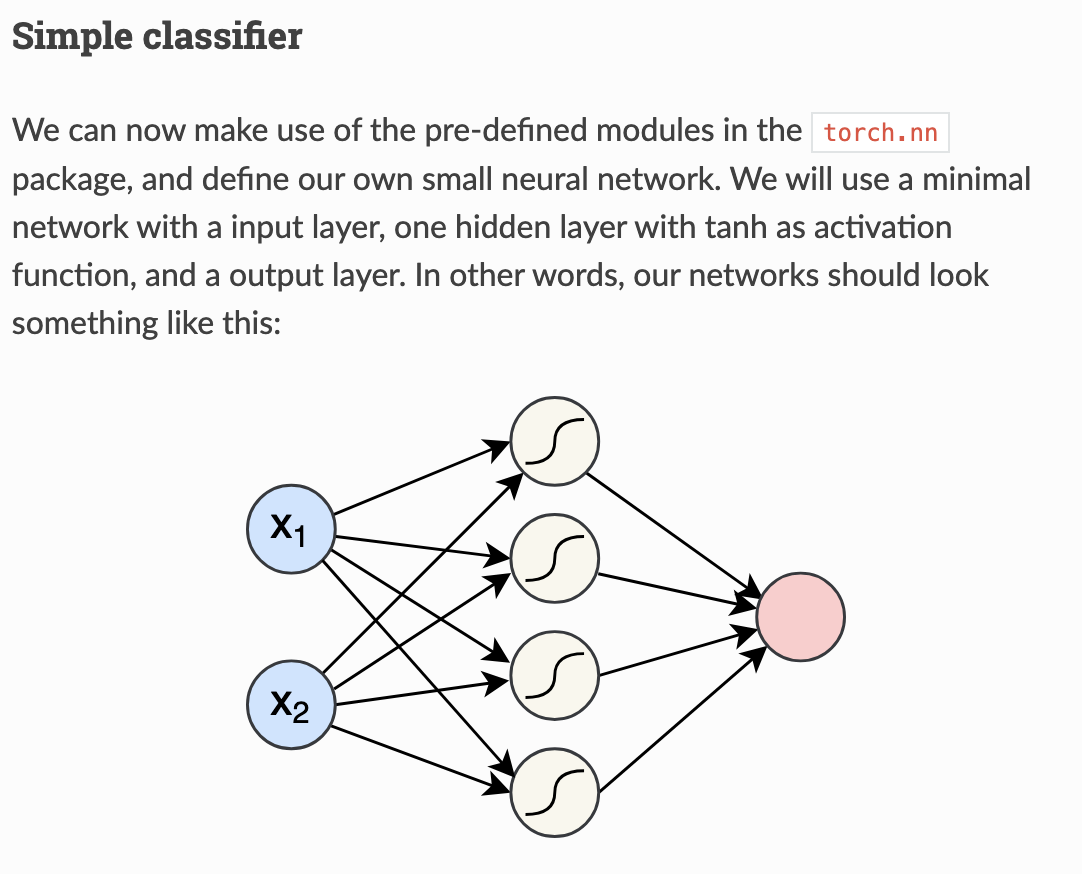

In [70]:
class SimpleClassifier(nn.Module):
    def __init__(self, num_inputs: int, num_hidden: int, num_outputs: int):
        super().__init__()
        # initlialise the modules needed to build the network
        self.linear_layer1 = nn.Linear(in_features=num_inputs,
                                       out_features=num_hidden)
        self.activation_fn = nn.Tanh()
        self.linear_layer2 = nn.Linear(in_features=num_hidden,
                                       out_features=num_outputs)

    def forward(self, x):
        # perform the calculation
        x = self.linear_layer1(x)
        x = self.activation_fn(x)
        x = self.linear_layer2(x)
        return x

In [71]:
model = SimpleClassifier(num_inputs=2, num_hidden=4, num_outputs=1)
model

SimpleClassifier(
  (linear_layer1): Linear(in_features=2, out_features=4, bias=True)
  (activation_fn): Tanh()
  (linear_layer2): Linear(in_features=4, out_features=1, bias=True)
)

In [72]:
# check the model parameters
for name, param in model.named_parameters():
    print(f"Parameter {name} of shape {param.shape}")

Parameter linear_layer1.weight of shape torch.Size([4, 2])
Parameter linear_layer1.bias of shape torch.Size([4])
Parameter linear_layer2.weight of shape torch.Size([1, 4])
Parameter linear_layer2.bias of shape torch.Size([1])


#### Data

In [73]:
import torch.utils.data as data

In [74]:
# __getitem__ has to return the i-th data point in the dataset
# __len__ returns the size of the dataset

class XORDataset(data.Dataset):
    def __init__(self, size, std=0.1):
        """
        Args:
            size (_type_): Number of data points we want to generate
            std (float, optional): The standard deviation of the noise Defaults to 0.1.
        """
        super().__init__()
        self.size = size
        self.std = std
        self.generate_continuous_xor()

    def generate_continuous_xor(self):
        # each datapoint in the XOR dataset has two vairables x and y, that can be either 0 or 1
        # the label is their XOR combination, i.e. 1 if only x or only y is 1 while the other is 0
        # if x=y, the label is 0
        data = torch.randint(low=0, high=2, size=(self.size, 2), dtype=torch.float32)
        label = (data.sum(dim=1) == 1).to(torch.long)
        # add a bit of gaussian noise to the data points
        data += self.std * torch.randn(data.shape)

        self.data = data
        self.label = label

    def __len__(self):
        return self.size

    def __getitem__(self, index):
        # if we have multiple things to return (data point and label), we return them as a tuple
        datapoint = self.data[index]
        label = self.label[index]
        return datapoint, label

In [75]:
dataset = XORDataset(size=200)
len(dataset), dataset[0]

(200, (tensor([1.0907, 0.7605]), tensor(0)))

In [76]:
def visualise_samples(data, label):
    if isinstance(data, torch.Tensor):
        data = data.cpu().numpy()
    if isinstance(label, torch.Tensor):
        label = label.cpu().numpy()


    data_0 = data[label == 0]
    data_1 = data[label == 1]

    plt.figure(figsize=(4,4))
    plt.scatter(data_0[:,0], data_0[:,1], edgecolors="#333", label="Class 0")
    plt.scatter(data_1[:,0], data_1[:,1], edgecolors="#333", label="Class 1")
    plt.title("Dataset samples")
    plt.ylabel(r"$x_2$")
    plt.xlabel(r"$x_1$")
    plt.legend()

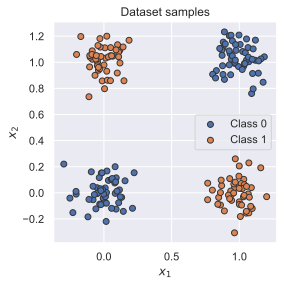

In [77]:
visualise_samples(dataset.data, dataset.label)
plt.show()

#### Dataloader class

In [78]:
dataloader = data.DataLoader(dataset, batch_size=8, shuffle=True)
dataloader

In [79]:
# get first batch of the dataloader
data_inputs, data_labels = next(iter(dataloader))

print(f"Shape of data inputs: {data_inputs.shape}")
print(f"Shape of data labels: {data_labels.shape}")

Shape of data inputs: torch.Size([8, 2])
Shape of data labels: torch.Size([8])


In [80]:
data_inputs

tensor([[ 0.0902, -0.1250],
        [-0.1051,  0.9646],
        [-0.0437,  1.0280],
        [-0.0340,  0.1162],
        [-0.0797, -0.0535],
        [ 1.0248,  1.0824],
        [ 0.1010,  1.1346],
        [ 0.9260,  0.9806]])

In [81]:
data_labels

tensor([0, 1, 1, 0, 0, 0, 1, 0])

In [82]:
for inputs, labels in dataloader:
    print(f"Shape of input batch: {inputs.shape}")
    print(f"Shape of labels batch: {labels.shape}")

Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])
Shape of labels batch: torch.Size([8])
Shape of input batch: torch.Size([8, 2])

In [83]:
len(dataloader)

25

#### Optimization

In [84]:
loss_fn = nn.BCEWithLogitsLoss()

In [85]:
optimizer_fn = torch.optim.SGD(model.parameters(), lr=0.1)

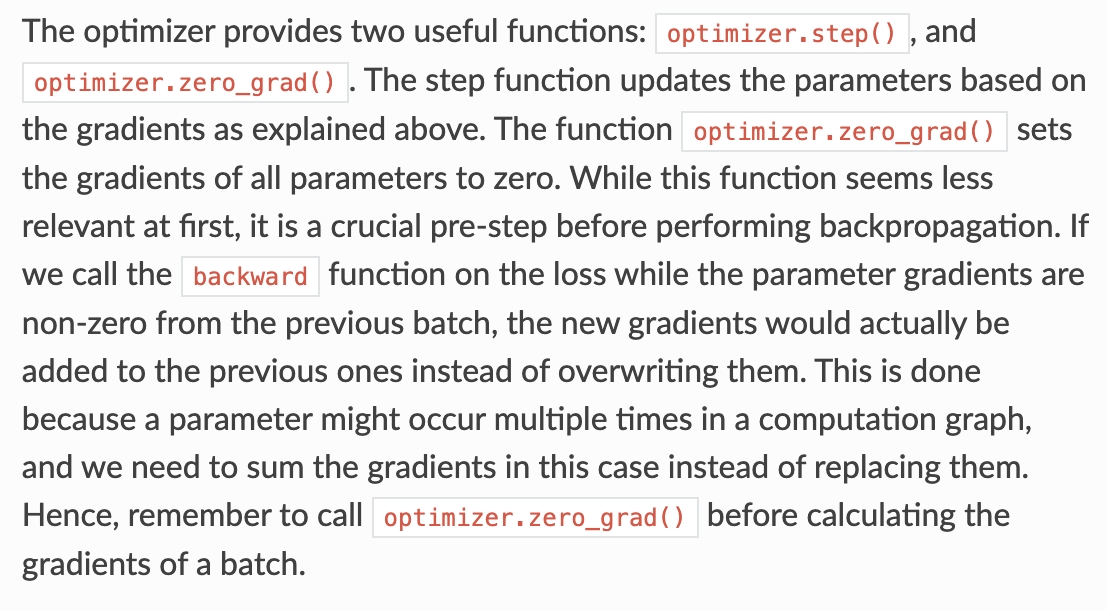

In [86]:
train_dataset = XORDataset(size=2500)
train_dataloader = data.DataLoader(train_dataset, batch_size=128, shuffle=True)

In [87]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
device

'mps'

In [88]:
model.to(device)

SimpleClassifier(
  (linear_layer1): Linear(in_features=2, out_features=4, bias=True)
  (activation_fn): Tanh()
  (linear_layer2): Linear(in_features=4, out_features=1, bias=True)
)

In [89]:
def train_model(model, optimizer, loss_fn, dataloader, num_epochs=100):
    # set model to train mode
    model.train()

    for epoch in tqdm(range(num_epochs)):

        for data_inputs, data_labels in dataloader:
            # move the data to the device
            data_inputs = data_inputs.to(device)
            data_labels = data_labels.to(device)

            # run the model on input data
            preds = model(data_inputs)
            preds = preds.squeeze(dim=1) # output is [Batach size, 1], we only want [Batch size]

            # compute loss
            loss = loss_fn(preds, data_labels.float())

            # set gradients to zero
            optimizer.zero_grad()
            # perform backpropagation
            loss.backward()

            # update parmeters
            optimizer.step()

In [90]:
train_model(model, optimizer_fn, loss_fn, train_dataloader)

  0%|          | 0/100 [00:00<?, ?it/s]

In [91]:
test_dataset = XORDataset(size=500)
test_dataloader = data.DataLoader(test_dataset, batch_size=128, shuffle=False, drop_last=False)

In [92]:
def eval_model(model, dataloader):
    model.eval() # set to eval mode
    true_preds, num_preds = 0., 0.

    with torch.no_grad(): # deactivate gradients
        for inputs, labels in dataloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            preds = model(inputs)
            preds = preds.squeeze(dim=1) # get only [Batch]

            preds = torch.sigmoid(preds) # maps predictions between 0 and 1
            pred_labels = (preds >= 0.5).long() # binarize predictions to 0 and 1

            # keep records of predictions for the accuracy metric
            # true_preds = TP+TN
            # num_preds = TP+TN+FP_FN
            true_preds += (pred_labels == labels).sum()
            num_preds += labels.shape[0]

    acc = true_preds / num_preds
    print(f"Accuracy of the model: {100.0 * acc : 4.2f}%")


In [93]:
eval_model(model, test_dataloader)

Accuracy of the model:  100.00%


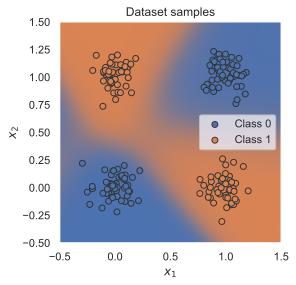

In [94]:
@torch.no_grad() # Decorator, same effect as "with torch.no_grad(): ..." over the whole function.
def visualize_classification(model, data, label):
    if isinstance(data, torch.Tensor):
        data = data.cpu().numpy()
    if isinstance(label, torch.Tensor):
        label = label.cpu().numpy()
    data_0 = data[label == 0]
    data_1 = data[label == 1]

    fig = plt.figure(figsize=(4,4), dpi=500)
    plt.scatter(data_0[:,0], data_0[:,1], edgecolor="#333", label="Class 0")
    plt.scatter(data_1[:,0], data_1[:,1], edgecolor="#333", label="Class 1")
    plt.title("Dataset samples")
    plt.ylabel(r"$x_2$")
    plt.xlabel(r"$x_1$")
    plt.legend()

    # Let's make use of a lot of operations we have learned above
    model.to(device)
    c0 = torch.Tensor(to_rgba("C0")).to(device)
    c1 = torch.Tensor(to_rgba("C1")).to(device)
    x1 = torch.arange(-0.5, 1.5, step=0.01, device=device)
    x2 = torch.arange(-0.5, 1.5, step=0.01, device=device)
    xx1, xx2 = torch.meshgrid(x1, x2, indexing='ij')  # Meshgrid function as in numpy
    model_inputs = torch.stack([xx1, xx2], dim=-1)
    preds = model(model_inputs)
    preds = torch.sigmoid(preds)
    output_image = (1 - preds) * c0[None,None] + preds * c1[None,None]  # Specifying "None" in a dimension creates a new one
    output_image = output_image.cpu().numpy()  # Convert to numpy array. This only works for tensors on CPU, hence first push to CPU
    plt.imshow(output_image, origin='lower', extent=(-0.5, 1.5, -0.5, 1.5))
    plt.grid(False)
    return fig

_ = visualize_classification(model, dataset.data, dataset.label)
plt.show()

## **PyTorch broadcasting semantics note**

- [ ] ([docs](https://docs.pytorch.org/docs/stable/notes/broadcasting.html)). Learn the two rules: align trailing dims, each pair must be equal, 1, or missing; then prepend 1s and take the max per dim. Also note that broadcasting expands without copying, and that in-place ops cannot change the left operand's shape.